In [1]:
import pandas as pd
import re
import string
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.model_selection import GridSearchCV

In [2]:
#1.1 - Loading the dataset into Jupyter and applying text denoising techniques

df = pd.read_json('research_abstracts.json')

df.head()

,DOI,Abstract,Label
0,10.1155/2021/1071145,Forward-looking forecasting of the inflation r...,ai
1,10.1007/s43546-022-00384-2,Our study examined the disaggregation of infla...,ai
2,10.1002/for.2667,This paper develops a dynamic factor model tha...,classical
3,10.1007/s42973-021-00091-x,"In this paper, I use a simple SIR Macro model ...",classical
4,10.1007/s40258-012-0003-z,BackgroundGame theory is useful for identifyin...,classical


In [3]:
#Removing any duplicates rows, duplicate abstracts, and resetting the index after removing the rows

df = df.dropna(subset=["Abstract"])
df = df.drop_duplicates(subset=["Abstract"])
df = df.reset_index(drop=True)

#Removing the DOI column since the NLP analysis focuses on abstract text
df = df.drop(columns=["DOI"])

In [4]:
#Now to apply text denoising

def denoise(text):

    #Converting to Lowercase
    text = text.lower()

    #Removing any URL'S
    text = re.sub(r'http\S+|www\S+', '', text)

    #Removing email addresses
    text = re.sub(r'\S+@\S+', '', text)

    #Removing HTML tags
    text = re.sub(r'<.*?>', '', text)

    #Removing punctuation
    text = text.translate(
        str.maketrans('', '', string.punctuation)
    )

    #Removing remaing special text
    text = re.sub(r'[^a-zA-Z0-9\s]', '', text)

    #Remving any spaces
    text = re.sub(r'\s+', ' ', text)

    #Removing any white space from start to end
    text = text.strip()

    return text

In [5]:
#Now to apply the cleaned dataset to a new dataframe

df["Cleaned_Abstract"] = df["Abstract"].apply(denoise)

In [6]:
#And finally, comparing the original dataset to the cleaned dataset

print("Original Abstract:\n")
print(df["Abstract"].iloc[0])

print("\n" + "=" * 80 + "\n")

print("Cleaned Abstract:\n")
print(df["Cleaned_Abstract"].iloc[0])

Original Abstract:

Forward-looking forecasting of the inflation rate could help the central bank and other government departments to better use monetary policy to stabilize prices and prevent the impact of inflation on market entities, especially for low- and middle-income groups. It can also help financial institutions and investors better make investment decisions. In this sense, the forecast of inflation rate is of great significance. The existing literature mainly uses linear models such as autoregressive (AR) and vector autoregressive (VAR) models to predict the inflation rate. The nonlinear relationship between variables and the mining of historical data information are relatively lacking. Therefore, the prediction strategies and accuracy of the existing literature need to be improved. The predictive model designed in deep learning can fully mine the nonlinear relationship between variables and process complex long-term time series dynamic information, thereby making up for the 

As per the above result, denoising techniques were applied to the 'Abstract' section of the dataset. Using the def denoise(text), this creates a customised Python fucntion that prevents the same cleaning instructions from repeating many times. Instead, one reusable fucnction is created to apply it to any text.

In [7]:
df.head()

,Abstract,Label,Cleaned_Abstract
0,Forward-looking forecasting of the inflation r...,ai,forwardlooking forecasting of the inflation ra...
1,Our study examined the disaggregation of infla...,ai,our study examined the disaggregation of infla...
2,This paper develops a dynamic factor model tha...,classical,this paper develops a dynamic factor model tha...
3,"In this paper, I use a simple SIR Macro model ...",classical,in this paper i use a simple sir macro model t...
4,BackgroundGame theory is useful for identifyin...,classical,backgroundgame theory is useful for identifyin...


In [8]:
#1.2 - Feature modelling using TF-IDF
#First, selecting the target variable and feature

X = df["Cleaned_Abstract"]
y = df["Label"]

#Before TF-IDF, split the abstracts into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y #approximately the same proportion of ai and classical labels within the both sets.
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

#Creating TF-IDF vectorizer
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=5000
)

#Converting the training data into TF-IDF numerical features
X_train_tfidf = tfidf.fit_transform(X_train)

#Applying to the test data
X_test_tfidf = tfidf.transform(X_test)

#Displaying the shape of the transformed dataset
print("TF-IDF training shape:", X_train_tfidf.shape)
print("TF-IDF testing shape:", X_test_tfidf.shape)

Training Samples: 900
Testing Samples: 225
TF-IDF training shape: (900, 5000)
TF-IDF testing shape: (225, 5000)


The dataset was split into training and test sets as the following question stiplulates to build a baseline model. I have chosen Logistic Regression.

In [9]:
#1.3 - Building the baseline model: Logistic Regression, and creating a performance report

model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

#Training the model
model.fit(X_train_tfidf, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [10]:
#Next, generating the prediction for the training and testing data

#Training
y_train_pred = model.predict(X_train_tfidf)

#Testing
y_test_pred = model.predict(X_test_tfidf)

In [11]:
#Next, the performance report, but first calculating accuracy then the rest of the metrics

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print("Training Accuracy:", round(train_accuracy, 4))
print("Testing Accuracy:", round(test_accuracy, 4))

Training Accuracy: 0.8878
Testing Accuracy: 0.8267


In [12]:
#Now for the classification report

print("Training Performance")
print(classification_report(y_train, y_train_pred))

print("\nTesting Performance")
print(classification_report(y_test, y_test_pred))

Training Performance
              precision    recall  f1-score   support

          ai       1.00      0.46      0.63       188
   classical       0.88      1.00      0.93       712

    accuracy                           0.89       900
   macro avg       0.94      0.73      0.78       900
weighted avg       0.90      0.89      0.87       900


Testing Performance
              precision    recall  f1-score   support

          ai       1.00      0.17      0.29        47
   classical       0.82      1.00      0.90       178

    accuracy                           0.83       225
   macro avg       0.91      0.59      0.60       225
weighted avg       0.86      0.83      0.77       225



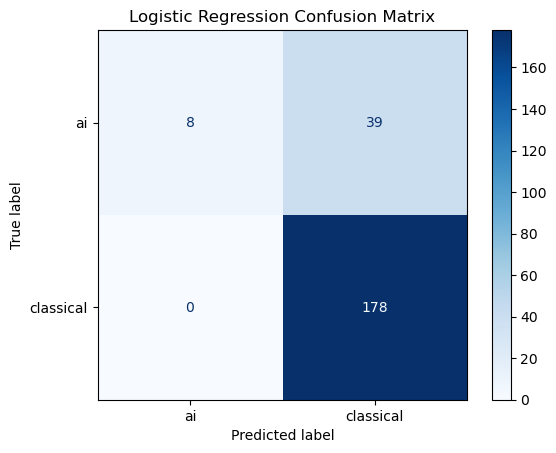

In [13]:
# Creating a Confusion Matrix for visualisation

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")
plt.show()

Report: The Logistic Regression model was chosen for this dataset as the baseline model. The model achieved a training accuracy of 88.78% and a testing accuracy of 82.67%. The slight difference between the two scores indicates that the model displayed the ability to generalise to unseen data. However, thr classification report revealed a critical class-level limitation and that is the model achieving as perfect precision score of 1.00, but a low recall score of 0.17 for the AI class. This means that predictions classified as AI were accurate but many genuine AI abstracts were inaccurately classified as classical. In contrast, the classical group achieved a recall score of 1.00 and an F1-Score of 0.90 on the test data. This may suggest that the model is biased to the majority of the classical class mainly due to the imbalance within the dataset. Therefore, while a test accuracy of 82.67% can be portayed as strong, the macro F1-Score of 0.60 details a more balanced indication of the model's performance across the both classes.

In [14]:
#Question 2
#2.1 - Building and fitting the 4 additional model. I have chosen: Linear SVM, Complement Naive Bayes, Random Forest, and SGD Classifier
#I have imported the necessary libraries at the begininning of the Notebook

#1. Linear SVM
svm_model = LinearSVC(
    class_weight="balanced",
    random_state=42
)

In [15]:
#2. Complement Naive Bayes
cnb_model = ComplementNB()

In [16]:
#3. Random Forest
random_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42
)

In [17]:
#4. SGD Classifier
sgd_model = SGDClassifier(
    loss="hinge",
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

In [18]:
#Now to train the models

svm_model.fit(X_train_tfidf, y_train)
cnb_model.fit(X_train_tfidf, y_train)
random_model.fit(X_train_tfidf, y_train)
sgd_model.fit(X_train_tfidf, y_train)

,loss,'hinge'
,penalty,'l2'
,alpha,0.0001
,l1_ratio,0.15
,fit_intercept,True
,max_iter,1000
,tol,0.001
,shuffle,True
,verbose,0
,epsilon,0.1
,n_jobs,None


In [19]:
#Now is the idel time to create a dictionary + loop

models = {
    "Linear SVM": svm_model,
    "Complement Naive Bayes": cnb_model,
    "Random Forest": random_model,
    "SGD Classifier": sgd_model
}

for name, model in models.items():

    y_train_pred = model.predict(X_train_tfidf)
    y_test_pred = model.predict(X_test_tfidf)

    #Calculating accuracy
    train_accuracy = accuracy_score(y_train, y_train_pred)
    test_accuracy = accuracy_score(y_test, y_test_pred)

    print("=" * 60)
    print(name)
    print("=" * 60)

    print(f"Training Accuracy: {train_accuracy:.4f}")
    print(f"Testing Accuracy: {test_accuracy:.4f}")

    print("\nClassfication Report:")
    print(classification_report(y_test, y_test_pred))

Linear SVM
Training Accuracy: 0.9989
Testing Accuracy: 0.8978

Classfication Report:
              precision    recall  f1-score   support

          ai       0.80      0.68      0.74        47
   classical       0.92      0.96      0.94       178

    accuracy                           0.90       225
   macro avg       0.86      0.82      0.84       225
weighted avg       0.89      0.90      0.89       225

Complement Naive Bayes
Training Accuracy: 0.9478
Testing Accuracy: 0.8667

Classfication Report:
              precision    recall  f1-score   support

          ai       0.87      0.43      0.57        47
   classical       0.87      0.98      0.92       178

    accuracy                           0.87       225
   macro avg       0.87      0.70      0.75       225
weighted avg       0.87      0.87      0.85       225

Random Forest
Training Accuracy: 1.0000
Testing Accuracy: 0.9156

Classfication Report:
              precision    recall  f1-score   support

          ai       1.

In [20]:
#A final comaprison table as this will make it easier for choosing the best overall model

results = []

for name, model in models.items():

    y_train_pred = model.predict(X_train_tfidf)
    y_test_pred = model.predict(X_test_tfidf)

    results.append({
        "Model": name,
        "Training Accuracy": accuracy_score(y_train, y_train_pred),
        "Testing Accuracy": accuracy_score(y_test, y_test_pred),
        "Precision": precision_score(y_test, y_test_pred, average="macro"),
        "Recall": recall_score(y_test, y_test_pred, average="macro"),
        "F1-Score": f1_score(y_test, y_test_pred, average="macro")
    })

results_df = pd.DataFrame(results)

print(results_df)

                    Model  Training Accuracy  Testing Accuracy  Precision  \
0              Linear SVM           0.998889          0.897778   0.859459   
1  Complement Naive Bayes           0.947778          0.866667   0.867951   
2           Random Forest           1.000000          0.915556   0.951777   
3          SGD Classifier           0.998889          0.915556   0.896777   

     Recall  F1-Score  
0  0.817954  0.836136  
1  0.704339  0.746241  
2  0.797872  0.848000  
3  0.837019  0.862208  


In [21]:
#2.2 - Next, an additional predictive performance enhancement. I have chosen Hyperparameter Tuning with GridSearchCV
#Now to tune all 4 models
#1. Linear SVM

svm_grid = GridSearchCV(
    LinearSVC(
        class_weight="balanced",
        random_state=42,
    ),
    param_grid={
        "C": [0.01, 0.1, 1, 10]
    },
    cv=5,
    scoring="f1_macro"
)

svm_grid.fit(X_train_tfidf, y_train)

print("Best SVM parameters:", svm_grid.best_params_)
print("Best SVM CV F1-Score:", svm_grid.best_score_)

Best SVM parameters: {'C': 1}
Best SVM CV F1-Score: 0.8261450327765225


In [22]:
#2. Complement Naive Bayes

cnb_grid = GridSearchCV(
    ComplementNB(),
    param_grid={
        "alpha": [0.1, 0.5, 1.0, 2.0]
    },
    cv=5,
    scoring="f1_macro"
)

cnb_grid.fit(X_train_tfidf, y_train)

print("Best CNB parameters:", cnb_grid.best_params_)
print("Best CNB CV F1-Score:", cnb_grid.best_score_)

Best CNB parameters: {'alpha': 0.5}
Best CNB CV F1-Score: 0.8166394640216922


In [23]:
#3. Random Forest

random_grid = GridSearchCV(
    RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
    ),
    param_grid={
        "n_estimators": [100, 200],
        "max_depth": [None, 20],
        "min_samples_split": [2, 5]
    },
    cv=5,
    scoring="f1_macro",
    n_jobs=-1
)

random_grid.fit(X_train_tfidf, y_train)

print("Best RF parameters:", random_grid.best_params_)
print("Best RF CV F1-Score:", random_grid.best_score_)

Best RF parameters: {'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 200}
Best RF CV F1-Score: 0.8273518558023392


In [24]:
#4. SGD Classifier

sgd_grid = GridSearchCV(
    SGDClassifier(
        loss="hinge",
        class_weight="balanced",
        random_state=42,
    ),
    param_grid={
        "alpha": [0.0001, 0.001, 0.01],
        "penalty": ["l2", "l1", "elasticnet"]
    },
    cv=5,
    scoring="f1_macro"
)

sgd_grid.fit(X_train_tfidf, y_train)

print("Best SGD parameters:", sgd_grid.best_params_)
print("Best SGD CV F1-Score:", sgd_grid.best_score_)

Best SGD parameters: {'alpha': 0.001, 'penalty': 'l1'}
Best SGD CV F1-Score: 0.8273926594085965


In [25]:
#Now to extract the best tined model versions

tuned_models = {
    "Linear SVM": svm_grid.best_estimator_,
    "Complement Naive Bayes": cnb_grid.best_estimator_,
    "Random Forest": random_grid.best_estimator_,
    "SGD Classifier": sgd_grid.best_estimator_
}

In [26]:
#Now to re-represent the model metrics after it has been tuned

tuned_results = []

for name, model in tuned_models.items():

    y_train_pred = model.predict(X_train_tfidf)
    y_test_pred = model.predict(X_test_tfidf)

    tuned_results.append({
        "Model": name,
        "Training Accuracy": accuracy_score(y_train, y_train_pred),
        "Testing Accuracy": accuracy_score(y_test, y_test_pred),
        "Precision": precision_score(y_test, y_test_pred, average="macro"),
        "Recall": recall_score(y_test, y_test_pred, average="macro"),
        "F1-Score": f1_score(y_test, y_test_pred, average="macro")
    })

tuned_results_df = pd.DataFrame(tuned_results)

print(tuned_results_df)

                    Model  Training Accuracy  Testing Accuracy  Precision  \
0              Linear SVM           0.998889          0.897778   0.859459   
1  Complement Naive Bayes           0.957778          0.902222   0.883835   
2           Random Forest           0.990000          0.911111   0.921350   
3          SGD Classifier           0.946667          0.902222   0.864396   

     Recall  F1-Score  
0  0.817954  0.836136  
1  0.805104  0.835962  
2  0.802893  0.844913  
3  0.828592  0.844613  


In [27]:
#2.3 - For the web0interface I will be using Streamlit. 
#And for the model, I have chosen the inital/untuned SGD Classifier model as it achieved the best overall predictive performance

#Saving the best performing model
joblib.dump(sgd_model, "sgd_model.pkl")

#Saving the fitted TF-IDF vectorizer
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Model and TF-IDF vectorizer has saved successfully!")

Model and TF-IDF vectorizer has saved successfully!


The use of pkl is stored as Python objects. The first file is the trained classifier and the second file contains the already fitted TF-IDF vectorizer.
This includes the vocabulary that has been learnt from the training data.
For the interface I have created a file called app.py and inputted the code in that file.
The best-performing classifier was deployed using Streamlit to provide a web-based interface for classifying unseen research abstracts. A user will enters or paste an abstract into the applications text box and clicks on the "Classify Abstract" button. The submitted text is first processed using the same denoising preprocessing techniques that was applied during model development. The saved TF-IDF vectorizer then transforms the processed abstract into the feature representation expected by the trained classifier. The model generates a prediction which is presented to the user as either Artificial Intelligence or Classical Research. Saving and reusing the fitted TF-IDF vectorizer ensures that new user input is represented using the same vocabulary and feature space used during model training.